<a href="https://colab.research.google.com/github/sanketkandalkar46-del/dsa-pp/blob/main/Dimensionality_Reduction_using_(PCA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import NecessaryLibraries


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

2. Load the Dataset:


In [2]:
# Load creditcard.csv uploaded to Google Colab
df = pd.read_csv('creditcard.csv')

# Drop non-feature columns if needed, define X and y
X = df.drop(columns=['Class'])
y = df['Class']

print("Original shape:", X.shape)

Original shape: (284807, 30)


3. Standardize the features

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled Data:\n", X_scaled)

Scaled Data:
 [[-1.99658302 -0.69424232 -0.04407492 ...  0.33089162 -0.06378115
   0.24496426]
 [-1.99658302  0.60849633  0.16117592 ... -0.02225568  0.04460752
  -0.34247454]
 [-1.99656197 -0.69350046 -0.81157783 ... -0.13713686 -0.18102083
   1.16068593]
 ...
 [ 1.6419735   0.98002374 -0.18243372 ...  0.01103672 -0.0804672
  -0.0818393 ]
 [ 1.6419735  -0.12275539  0.32125034 ...  0.26960398  0.31668678
  -0.31324853]
 [ 1.64205773 -0.27233093 -0.11489898 ... -0.00598394  0.04134999
   0.51435531]]


Calculate covariance structure

In [4]:
cov_matrix = np.cov(X_scaled, rowvar=False)
print("Covariance Matrix Shape:", cov_matrix.shape)

Covariance Matrix Shape: (30, 30)


5. Apply PCA

In [5]:
# PCA for 2 components
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

print("Before PCA:", X.shape)
print("After PCA (2 components):", X_pca_2.shape)

# Explained Variance
print("Explained Variance Ratio (2 PCs):", pca_2.explained_variance_ratio_)
total_variance = sum(pca_2.explained_variance_ratio_)
print("Variance retained:", total_variance)

# Retaining 95% Variance
pca_95 = PCA(n_components=0.95)
X_pca_95 = pca_95.fit_transform(X_scaled)

print("Original features:", X.shape[1])
print("Reduced features (95% variance):", X_pca_95.shape[1])

Before PCA: (284807, 30)
After PCA (2 components): (284807, 2)
Explained Variance Ratio (2 PCs): [0.06527521 0.05612313]
Variance retained: 0.12139834577465444
Original features: 30
Reduced features (95% variance): 27


6. Visualization using first two PCs

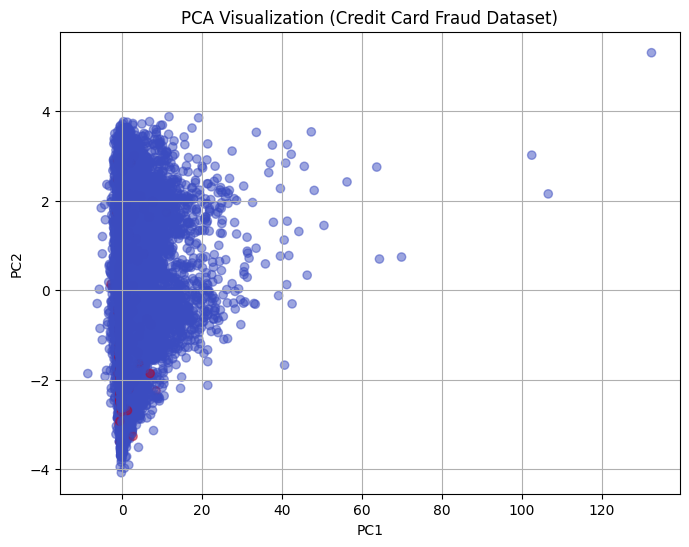

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap='coolwarm', alpha=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization (Credit Card Fraud Dataset)")
plt.grid(True)
plt.show()

7. Classification Performance: Before PCA

In [7]:
X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(
    X_scaled, y, train_size=0.8, random_state=42, stratify=y
)

start = time.time()
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
pred = model.predict(X_test_scaled)
end = time.time()

accuracy_before = accuracy_score(y_test, pred)
print("Accuracy without PCA:", accuracy_before)
print("Execution time without PCA:", end - start, "seconds")

Accuracy without PCA: 0.9991573329588147
Execution time without PCA: 0.6395134925842285 seconds


8. Classification Performance: After PCA

In [8]:
X_train_pca, X_test_pca, y_train, y_test = train_test_split(
    X_pca_95, y, train_size=0.8, random_state=42, stratify=y
)

start = time.time()
model_pca = LogisticRegression(max_iter=1000)
model_pca.fit(X_train_pca, y_train)
pred_pca = model_pca.predict(X_test_pca)
end = time.time()

accuracy_after = accuracy_score(y_test, pred_pca)
print("Accuracy with PCA:", accuracy_after)
print("Execution time with PCA:", end - start, "seconds")

Accuracy with PCA: 0.9991924440855307
Execution time with PCA: 0.7518877983093262 seconds
